# 01 · Reality check: how good is Katip on real text?

**Katip lab, notebook 1 of 3.** About 5 minutes.

### The question

Katip finds 99.9% of names on its blind set. That set is synthetic. **How many names does Katip
find in real Turkish sentences, written by people, about people?**

### Why it matters

Names are the hardest KVKK value: TCKN, IBAN and phone numbers have checksums and formats; names
don't. A missed name is a leak. If the 99.9% only holds on our own templates, every claim built on
it (pilot bar, README, sales deck) is at risk.

### Rules of the game

* We look **only at the dev split** here. The test split stays sealed until notebook 3, so nothing
  we learn from errors today can leak into the final number.
* We score names the way Katip always has (`katiplab.matches`): a gold name counts as found when a
  detected span covers it.
* Every number gets a 95% confidence interval from a **document-level bootstrap**: we resample whole
  sentences/documents 2,000 times, because names in one document are not independent.

In [1]:
import json, re
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt
import katiplab as K

sets = {
    "blind (synthetic)":   K.load_synth("blind"),
    "heldout (synthetic)": K.load_synth("heldout"),
    "negatives (no names)": K.load_synth("negatives"),
    "wiki dev (real)":     K.load_wiki("dev"),
}
for k, v in sets.items():
    print(f"{k:22} {len(v):5} docs  {sum(t == 'PERSON' for d in v for *_, t in d['spans']):4} names")

blind (synthetic)         80 docs   365 names
heldout (synthetic)       60 docs   275 names
negatives (no names)       3 docs     0 names
wiki dev (real)         1000 docs   641 names


## 1.1 · Contamination check

Before trusting a test, check that it does not overlap with training material:

* the same sentence in two Wiki NER splits,
* names that appear both in Katip's synthetic training data and the real dev set (those are easier
  for the model; we count them and report recall on the unseen ones separately later).

In [2]:
wtrain, wtest = K.load_wiki("train"), K.load_wiki("test")
dup = lambda a, b: len({d["text"] for d in a} & {d["text"] for d in b})
print("identical sentences  train∩dev:", dup(wtrain, sets["wiki dev (real)"]), " train∩test:", dup(wtrain, wtest),
      " dev∩test:", dup(sets["wiki dev (real)"], wtest))

synth_train = K.load_synth("train")
synth_names = {d["text"][a:b] for d in synth_train for a, b, t in d["spans"] if t == "PERSON"}
dev_names = [d["text"][a:b] for d in sets["wiki dev (real)"] for a, b, t in d["spans"] if t == "PERSON"]
print(f"dev names also in Katip's synthetic training data: {sum(n in synth_names for n in dev_names)} of {len(dev_names)}")

identical sentences  train∩dev: 0  train∩test: 0  dev∩test: 0


dev names also in Katip's synthetic training data: 3 of 641


## 1.2 · The systems

| system | what it is | size |
| --- | --- | --- |
| **Rules** | Katip's Turkish rules (gazetteers, cue words, casing, suffixes) | 0.3 MB |
| **Tiny, model only** | the 2.6 MB tagger by itself | 2.6 MB |
| **Tiny pipeline** | rules + tagger with the browser's merge policy, *what the demo runs* | 2.9 MB |
| **BERTurk** (if you trained it) | your 110 MB fine-tune, alone and in the pipeline (trust 0.9) | 110.8 MB |

(The open-source `kvkk-pii` baseline from the README is left out: its regex layer has no name
detector, so it finds 0 names on every set.)

The merge policy matters: in the pipeline, a model-only name is kept only if it has **at least two
capitalised words** (so "Tonio" alone is dropped). That rule was added because the tagger alone
produced 100+ false names on synthetic documents.

In [3]:
tiny = K.Tagger(K.TINY)
systems = {
    "Rules":               K.rules(),
    "Tiny, model only":    K.model_only(tiny),
    "Tiny pipeline":       K.pipeline(tiny),
}
if (K.BERTURK / "onnx" / "model_quantized.onnx").exists():
    bert = K.Tagger(K.BERTURK)
    systems["BERTurk, model only"] = K.model_only(bert)
    systems["BERTurk pipeline"] = K.pipeline(bert, trust=0.9)

R = {}
for name, det in systems.items():
    R[name] = K.evaluate(name, det, sets)
    print("scored", name)

scored Rules


scored Tiny, model only


scored Tiny pipeline


In [4]:
def table(R, metric="recall"):
    rows = []
    for sysname, by in R.items():
        row = {"system": sysname}
        for sname, r in by.items():
            if sname.startswith("negatives"):
                row["false names on name-free text"] = r["false"]
            else:
                lo, hi = r[f"{metric}_ci"]
                row[sname] = f"{r[metric]:.1%}  [{lo:.1%}–{hi:.1%}]"
        rows.append(row)
    return pd.DataFrame(rows).set_index("system")

print("NAME RECALL (share of names found), 95% CI")
table(R, "recall")

NAME RECALL (share of names found), 95% CI


,blind (synthetic),heldout (synthetic),false names on name-free text,wiki dev (real)
system,,,,
Rules,98.4% [96.4%–99.7%],95.3% [91.8%–98.2%],2,10.3% [7.7%–13.3%]
"Tiny, model only",78.1% [72.8%–82.9%],96.0% [91.8%–99.3%],45,24.2% [20.4%–28.1%]
Tiny pipeline,99.7% [99.1%–100.0%],97.5% [94.8%–99.6%],2,10.9% [8.2%–14.1%]


In [5]:
print("NAME PRECISION (share of name highlights that are real names), 95% CI")
table(R, "precision")

NAME PRECISION (share of name highlights that are real names), 95% CI


,blind (synthetic),heldout (synthetic),false names on name-free text,wiki dev (real)
system,,,,
Rules,100.0% [100.0%–100.0%],100.0% [100.0%–100.0%],2,53.5% [43.1%–63.6%]
"Tiny, model only",89.5% [84.8%–93.7%],99.7% [98.9%–100.0%],45,14.8% [12.7%–16.9%]
Tiny pipeline,100.0% [100.0%–100.0%],100.0% [100.0%–100.0%],2,53.3% [43.7%–63.3%]


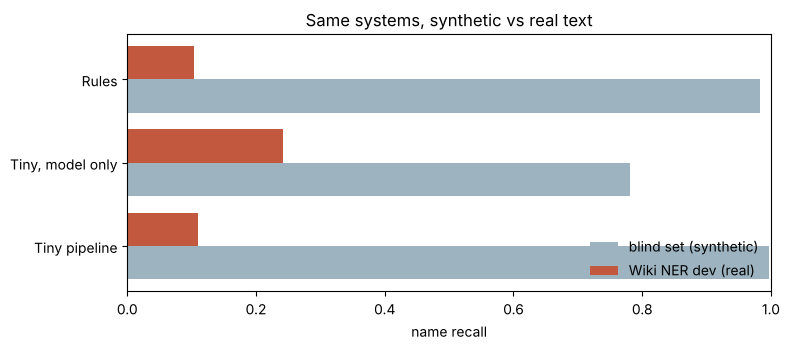

In [6]:
names = list(R)
syn = [R[n]["blind (synthetic)"]["recall"] for n in names]
real = [R[n]["wiki dev (real)"]["recall"] for n in names]
fig, ax = plt.subplots(figsize=(8, 3.6))
y = range(len(names))
ax.barh([i + 0.2 for i in y], syn, 0.4, label="blind set (synthetic)", color="#9db4c0")
ax.barh([i - 0.2 for i in y], real, 0.4, label="Wiki NER dev (real)", color="#c2593f")
ax.set_yticks(list(y), names); ax.invert_yaxis(); ax.set_xlim(0, 1); ax.set_xlabel("name recall")
ax.legend(loc="lower right", frameon=False); ax.set_title("Same systems, synthetic vs real text")
plt.tight_layout(); plt.show()

**Checkpoint.** Write down, in one sentence, the gap you see between the two bars for *Tiny
pipeline*. That sentence is the problem statement of this study.

## 1.3 · Where do the misses come from?

Three cuts, each a hypothesis about *why* names are missed:

* **origin**: Turkish names (in Katip's name lists) vs everything else (foreign, rare, nicknames),
* **length**: one-word names ("Tonio") vs two or more words,
* **case suffix**: names written with an apostrophe suffix ("Medea'nın").

Careful reading: the Rules use the same name lists that define "Turkish" here, so Rules are
expected to look better on that slice. The cut is still useful for the model.

In [7]:
def cuts(gold_rows):
    df = pd.DataFrame(gold_rows)
    df["words"] = df.text.str.split().str.len().clip(upper=2).map({1: "1 word", 2: "2+ words"})
    df["suffix"] = df.text.str.contains("['’]").map({True: "with 'suffix", False: "no suffix"})
    out = {}
    for col in ("origin", "words", "suffix"):
        for k, g in df.groupby(col): out[(col, k)] = f"{g.found.mean():.0%} of {len(g)}"
    return out

pd.DataFrame({n: cuts(R[n]["wiki dev (real)"]["_rows"][0]) for n in R}).T

origin                  words                  suffix  \
                       other    turkish      1 word    2+ words   no suffix   
Rules              5% of 576  60% of 65   2% of 295  17% of 346  10% of 462   
Tiny, model only  20% of 576  57% of 65  27% of 295  22% of 346  27% of 462   
Tiny pipeline      5% of 576  60% of 65   2% of 295  18% of 346  11% of 462   

                               
                 with 'suffix  
Rules              10% of 179  
Tiny, model only   17% of 179  
Tiny pipeline      10% of 179

In [8]:
g, s = R["Tiny pipeline"]["wiki dev (real)"]["_rows"]
print("20 missed names (Tiny pipeline):")
print([r["text"] for r in g if not r["found"]][:20])
print()
print("false name highlights by kind:", Counter(r["kind"] for r in s if r["false"]))
print([r["text"] for r in s if r["false"]][:15])

20 missed names (Tiny pipeline):
['Mao', 'Gramsci', 'Leon Bourgeois', 'Chagas', 'Martin Luther', 'Ansara', "Jeremy Irons'ın", 'Valentin', 'Eldar Kasımov', 'Ell & Nikki', 'Randy', 'Punk', 'Taneli Jarva', 'Mrrgan', 'Morrgan', 'Morrgu', 'Morrghan', 'Mor Roghain', 'Morrgna', 'Papazov']

false name highlights by kind: Counter({'other entity': 60, 'plain words': 3})
['Glas Slavonije', 'Büyükşehir Belediyespor', 'Çeçence, Bats', 'Allaire', 'Jeremy Allaire', 'Allaire', 'Rapid Bükreş', 'Güney Sumatra', 'Sumatra', 'İslam', 'Özel Türk', 'Wembley Stadı', 'Çetin Cengiz Dance Group', 'Hakan Peker Dance Group', 'Sema Tekin Dance Group']


In [9]:
g, s = R["Tiny, model only"]["wiki dev (real)"]["_rows"]
print("Tiny, model only: false highlights by kind:", Counter(r["kind"] for r in s if r["false"]))
print([r["text"] for r in s if r["false"] and r["kind"] == "plain words"][:20])

Tiny, model only: false highlights by kind: Counter({'plain words': 837, 'other entity': 671})
['önemli', 'şehri', 'hükümetinde', 'ölmüştür.', 'öteki', 'özelliği', 'çok', 'Astımda', 'KOAH', 'sağaltımında', 'sırasında', 'şimdiki', 'hazırlanmıştır.', 'çıktı.', 'ünvanını', 'çıktı', 'sağlayan', 'Belli', 'süre', 'üzerinden']


### Why would a name tagger mark *önemli* as a name?

A hypothesis you can test in one cell: the tiny model has its own 16,000-piece vocabulary, learned
from the synthetic documents only, and that vocabulary is full of names. Ordinary Turkish words that
never occur in the templates get chopped into small pieces (`ö ##nem ##li`), and in the training
data, *chopped into rare pieces* mostly happened to names. If so, false highlights should be words
the tokenizer splits much more than average.

In [10]:
import regex, statistics
pieces = lambda w: len(tiny.tok.encode(w, add_special_tokens=False).ids)
all_words = [m.group() for d in sets["wiki dev (real)"] for m in regex.finditer(r"\p{L}+", d["text"]) if m.group()[0].islower()]
fp_words = [w for r in s if r["false"] and r["kind"] == "plain words" for w in r["text"].split() if w[0].islower()]
print(f"pieces per lowercase word, all dev text:       {statistics.mean(map(pieces, all_words)):.2f}")
print(f"pieces per lowercase word, false name highlights: {statistics.mean(map(pieces, fp_words)):.2f}")
first = lambda ws: sum(not w[0].isascii() for w in ws) / len(ws)
print(f"share starting with ç ğ ı ö ş ü: all {first(all_words):.0%}, false highlights {first(fp_words):.0%}")
for w in ["önemli", "şehri", "çok", "sırasında", "şirket", "Ahmet"]:
    print(f"  {w:10} -> {tiny.tok.encode(w, add_special_tokens=False).tokens}")

pieces per lowercase word, all dev text:       2.42
pieces per lowercase word, false name highlights: 3.33
share starting with ç ğ ı ö ş ü: all 7%, false highlights 54%
  önemli     -> ['ö', '##nem', '##li']
  şehri      -> ['ş', '##eh', '##ri']
  çok        -> ['ç', '##ok']
  sırasında  -> ['sı', '##ra', '##sı', '##n', '##da']
  şirket     -> ['şirket']
  Ahmet      -> ['Ahmet']


**What to look for.**

* The tagger by itself finds more real names than the pipeline, but with very low precision: it
  marks ordinary words (`önemli`, `şehir`) as names. It learned *where names sit in Katip's
  templates* and *"rare pieces = name"*, not *what a name looks like in Turkish prose*.
* The pipeline's merge policy then filters most of those out, and with them most of the real
  one-word names.
* Many "false" names are other entities (places, organisations, song titles). For KVKK these are
  over-masking, which is cheap. Highlights on plain words are the real cost.

## 1.4 · Save

Everything is written to `results/01_reality.json` (without the raw rows) for the report.

In [11]:
slim = {n: {s: {k: v for k, v in r.items() if k != "_rows"} for s, r in by.items()} for n, by in R.items()}
(K.RESULTS / "01_reality.json").write_text(json.dumps(slim, indent=1, ensure_ascii=False))
print("saved", K.RESULTS / "01_reality.json")

saved <repo>/lab/results/01_reality.json


## Conclusion you should be able to state

> On real Turkish sentences, Katip's name recall falls from ~99% (synthetic) to the figure you just
> measured. The 2.6 MB tagger has the capacity to help, but it was trained only on templated
> documents, so on real prose it confuses ordinary words with names.

That gives a falsifiable hypothesis for notebook 2: **the model is not too small, its data is too
narrow.** If that is true, mixing a modest amount of real, human-labelled text into training should
raise real-text recall a lot **at the same 2.6 MB**, without hurting the synthetic scores.